In [1]:
import sys
print("Python version:", sys.version)
print("Python location:", sys.executable)
print("-" * 40)

libraries = ["pandas", "numpy", "matplotlib", "seaborn", "sklearn", "joblib", "streamlit"]

for lib in libraries:
    try:
        module = __import__(lib)
        print(f"{lib:12} OK    version {module.__version__}")
    except ImportError:
        print(f"{lib:12} MISSING")

Python version: 3.13.12 (tags/v3.13.12:1cbe481, Feb  3 2026, 18:22:25) [MSC v.1944 64 bit (AMD64)]
Python location: C:\Users\uzair\AppData\Local\Programs\Python\Python313\python.exe
----------------------------------------
pandas       OK    version 3.0.6
numpy        OK    version 2.5.3
matplotlib   OK    version 3.11.2
seaborn      OK    version 0.13.2
sklearn      OK    version 1.9.1
joblib       OK    version 1.6.0
streamlit    OK    version 1.65.0


In [2]:
import os
import urllib.request
import zipfile

# 1. Show which folder the notebook is working in
print("Working folder:", os.getcwd())

# 2. Create a folder called "data" to keep the dataset files
os.makedirs("data", exist_ok=True)

# 3. Official UCI download link for dataset #45 (Heart Disease)
url = "https://archive.ics.uci.edu/static/public/45/heart+disease.zip"
zip_path = os.path.join("data", "heart+disease.zip")

# 4. Download the zip file (we send a browser-like header so the server accepts us)
request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(request) as response, open(zip_path, "wb") as f:
    f.write(response.read())
print("Downloaded:", zip_path)

# 5. Unzip everything into the data folder
with zipfile.ZipFile(zip_path) as z:
    z.extractall("data")

# 6. List the files we received
print("\nFiles in the data folder:")
for name in sorted(os.listdir("data")):
    size_kb = os.path.getsize(os.path.join("data", name)) / 1024
    print(f"  {name:45} {size_kb:8.1f} KB")

Working folder: C:\Users\uzair
Downloaded: data\heart+disease.zip

Files in the data folder:
  Index                                              0.6 KB
  WARNING                                            0.4 KB
  ask-detrano                                        0.6 KB
  bak                                                6.6 KB
  cleve.mod                                         23.4 KB
  cleveland.data                                    59.2 KB
  costs                                              4.0 KB
  heart+disease.zip                                125.9 KB
  heart-disease.names                                9.8 KB
  hungarian.data                                    60.7 KB
  long-beach-va.data                                39.0 KB
  new.data                                         380.6 KB
  processed.cleveland.data                          18.0 KB
  processed.hungarian.data                          10.0 KB
  processed.switzerland.data                         4.0 KB
  proce

In [3]:
# Part 1: show the first 5 raw lines of the Cleveland file
print("=== First 5 raw lines of processed.cleveland.data ===")
with open("data/processed.cleveland.data", "r") as f:
    lines = f.readlines()
for line in lines[:5]:
    print(line.strip())
print("Total lines in file:", len(lines))

# Part 2: print the attribute description from the official documentation
print("\n=== Attribute section of heart-disease.names ===")
with open("data/heart-disease.names", "r", errors="ignore") as f:
    doc_lines = f.readlines()

start = 0
for i, line in enumerate(doc_lines):
    if "Attribute Information" in line:
        start = i
        break

for line in doc_lines[start:start + 70]:
    print(line.rstrip())

=== First 5 raw lines of processed.cleveland.data ===
63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
Total lines in file: 303

=== Attribute section of heart-disease.names ===
7. Attribute Information:
   -- Only 14 used
      -- 1. #3  (age)
      -- 2. #4  (sex)
      -- 3. #9  (cp)
      -- 4. #10 (trestbps)
      -- 5. #12 (chol)
      -- 6. #16 (fbs)
      -- 7. #19 (restecg)
      -- 8. #32 (thalach)
      -- 9. #38 (exang)
      -- 10. #40 (oldpeak)
      -- 11. #41 (slope)
      -- 12. #44 (ca)
      -- 13. #51 (thal)
      -- 14. #58 (num)       (the predicted attribute)

   -- Complete attribute documentation:
      1 id: patient identification number
      2 ccf: social security number (I replaced this with a dummy value 

In [4]:
import pandas as pd

# The 14 column names, in the order given by the official documentation
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# Load the file. header=None: the file has no header row.
# names=column_names: we provide the names.
# na_values="?": treat "?" as a missing value, if the file uses it.
df = pd.read_csv("data/processed.cleveland.data",
                 header=None, names=column_names, na_values="?")

print("Rows and columns:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn data types:")
print(df.dtypes)

# Show the rest of the documentation (the part cut off last time)
print("\n=== Documentation, continued ===")
with open("data/heart-disease.names", "r", errors="ignore") as f:
    doc_lines = f.readlines()
start = [i for i, l in enumerate(doc_lines) if "Attribute Information" in l][0]
for line in doc_lines[start + 70 : start + 115]:
    print(line.rstrip())
    

Rows and columns: (303, 14)

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Column data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64
dtype: object

=== Documentation, continued ===
     30 thaltime: time when ST measure depression was noted
     31 met: mets achieved
     32 thalach: maximum heart rate achieved
     33 thalrest: resting heart rate
     34 tpeakbps: peak exercise blood pressure (first of 2 parts)
     35 tpeakbpd: peak exercise blood pressure (second of 2 parts)
     36 dummy
     37 trestbpd: resting blood pressure
     38 exang: exercise induced angina (1 = yes; 0 = no)
     39 xhypo: (1 = yes; 0 = no)
     40 oldpeak = ST depression induced by exercise relative to rest
     41 slope: the slope of the peak exercise ST segment
        -- Value 1: upsloping
        -- Value 2: flat
        -- Value 3: down

=== Missing values per column ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

=== Number of duplicate rows ===
0

=== Basic statistics ===


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00



=== Values in the target column 'num' ===
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


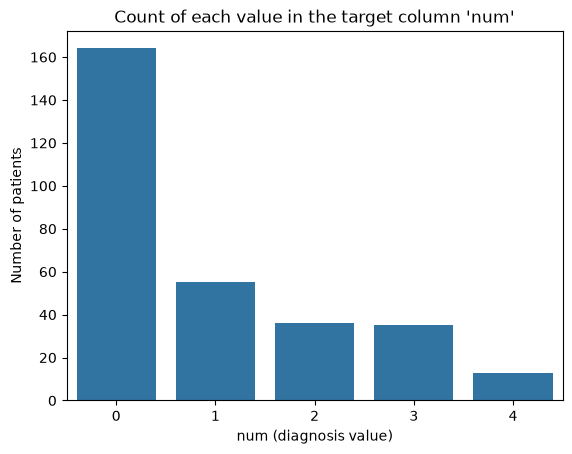

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=== Missing values per column ===")
print(df.isnull().sum())

print("\n=== Number of duplicate rows ===")
print(df.duplicated().sum())

print("\n=== Basic statistics ===")
display(df.describe().round(2))

print("\n=== Values in the target column 'num' ===")
print(df["num"].value_counts().sort_index())

# Bar chart of the target values
sns.countplot(x="num", data=df)
plt.title("Count of each value in the target column 'num'")
plt.xlabel("num (diagnosis value)")
plt.ylabel("Number of patients")
plt.show()

       --


          -- Instance-based prediction of heart-disease presence with the
             Cleveland database
             -- NTgrowth: 77.0% accuracy
----------------------------------------
     This database contains 76 attributes, but all published experiments
     refer to using a subset of 14 of them.  In particular, the Cleveland
     database is the only one that has been used by ML researchers to
     this date.  The "goal" field refers to the presence of heart disease
     in the patient.  It is integer valued from 0 (no presence) to 4.
     Experiments with the Cleveland database have concentrated on simply
----------------------------------------
     refer to using a subset of 14 of them.  In particular, the Cleveland
     database is the only one that has been used by ML researchers to
     this date.  The "goal" field refers to the presence of heart disease
     in the patient.  It is integer valued from 0 (no presence) to 4.
     Experiments with the Cleveland d

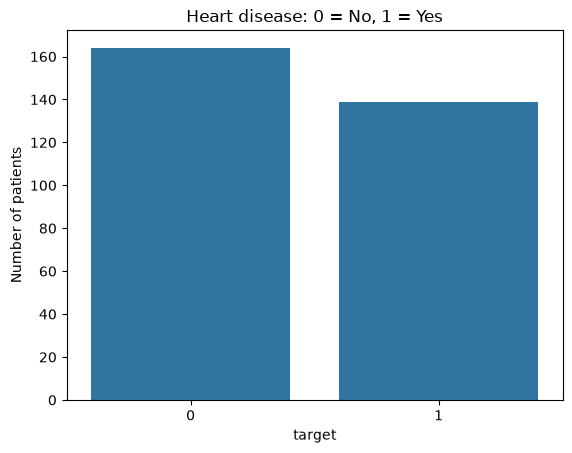

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# Part 1: print what the official documentation says about the "goal" field
with open("data/heart-disease.names", "r", errors="ignore") as f:
    doc_lines = f.readlines()

for i, line in enumerate(doc_lines):
    if "presence" in line.lower():
        for l in doc_lines[max(0, i - 3): i + 3]:
            print(l.rstrip())
        print("-" * 40)

# Part 2: create a binary target: 0 = no disease, 1 = disease (num 1, 2, 3 or 4)
df["target"] = (df["num"] > 0).astype(int)

print("\nBinary target counts:")
print(df["target"].value_counts().sort_index())
print("\nPercentages:")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(1))

# Part 3: chart
sns.countplot(x="target", data=df)
plt.title("Heart disease: 0 = No, 1 = Yes")
plt.xlabel("target")
plt.ylabel("Number of patients")
plt.show()

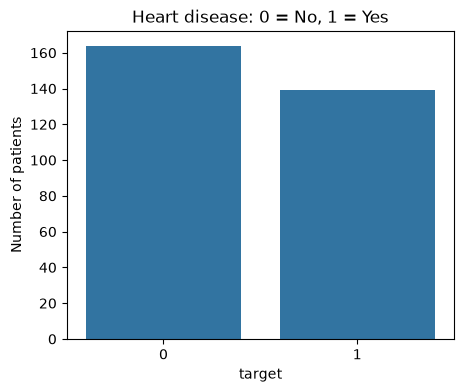

Average values by target:
         age  trestbps   chol  thalach  oldpeak
target                                         
0       52.6     129.2  242.6    158.4      0.6
1       56.6     134.6  251.5    139.3      1.6

Disease rate (%) by sex:
sex
0.0    25.8
1.0    55.3
Name: target, dtype: float64

Disease rate (%) by cp:
cp
1.0    30.4
2.0    18.0
3.0    20.9
4.0    72.9
Name: target, dtype: float64

Disease rate (%) by exang:
exang
0.0    30.9
1.0    76.8
Name: target, dtype: float64

Disease rate (%) by fbs:
fbs
0.0    45.3
1.0    48.9
Name: target, dtype: float64

Disease rate (%) by restecg:
restecg
0.0    37.1
1.0    75.0
2.0    54.1
Name: target, dtype: float64


In [7]:
plt.close("all")                      # close any old figures left in the background

fig, ax = plt.subplots(figsize=(5, 4))   # start a fresh, empty figure
sns.countplot(x="target", data=df, ax=ax)
ax.set_title("Heart disease: 0 = No, 1 = Yes")
ax.set_xlabel("target")
ax.set_ylabel("Number of patients")
plt.show()

# Average of numeric columns for healthy (0) vs sick (1) patients
print("Average values by target:")
print(df.groupby("target")[["age", "trestbps", "chol", "thalach", "oldpeak"]].mean().round(1))

# Percentage of patients WITH disease inside each category
for col in ["sex", "cp", "exang", "fbs", "restecg"]:
    print(f"\nDisease rate (%) by {col}:")
    print((df.groupby(col)["target"].mean() * 100).round(1))

In [8]:
# The 4 input features. Keep this exact order everywhere in the project.
FEATURES = ["sex", "cp", "thalach", "exang"]

X = df[FEATURES].copy()    # inputs: what the model sees
y = df["target"]           # output: what the model predicts (0 = no disease, 1 = disease)

print("Number of features:", len(FEATURES))
print("X shape:", X.shape, "| y shape:", y.shape)
print("Feature names:", list(X.columns))
print("Is 'num' in X?   ", "num" in X.columns)
print("Is 'target' in X?", "target" in X.columns)

print("\nMissing values in X:")
print(X.isnull().sum())

print("\nFirst 5 rows of X:")
display(X.head())

print("\nValue counts:")
for col in ["sex", "cp", "exang"]:
    print(f"\n{col}:")
    print(X[col].value_counts().sort_index())

print("\nthalach summary:")
print(X["thalach"].describe().round(1))

Number of features: 4
X shape: (303, 4) | y shape: (303,)
Feature names: ['sex', 'cp', 'thalach', 'exang']
Is 'num' in X?    False
Is 'target' in X? False

Missing values in X:
sex        0
cp         0
thalach    0
exang      0
dtype: int64

First 5 rows of X:


,sex,cp,thalach,exang
0,1.0,1.0,150.0,0.0
1,1.0,4.0,108.0,1.0
2,1.0,4.0,129.0,1.0
3,1.0,3.0,187.0,0.0
4,0.0,2.0,172.0,0.0



Value counts:

sex:
sex
0.0     97
1.0    206
Name: count, dtype: int64

cp:
cp
1.0     23
2.0     50
3.0     86
4.0    144
Name: count, dtype: int64

exang:
exang
0.0    204
1.0     99
Name: count, dtype: int64

thalach summary:
count    303.0
mean     149.6
std       22.9
min       71.0
25%      133.5
50%      153.0
75%      166.0
max      202.0
Name: thalach, dtype: float64


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Check the four features for invalid values
print("sex values   :", sorted(X["sex"].unique()))
print("cp values    :", sorted(X["cp"].unique()))
print("exang values :", sorted(X["exang"].unique()))
print("thalach range:", X["thalach"].min(), "to", X["thalach"].max())

# 2. Describe (but do NOT fit yet) the preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("cp_onehot", OneHotEncoder(handle_unknown="ignore"), ["cp"]),
        ("thalach_scale", StandardScaler(), ["thalach"]),
    ],
    remainder="passthrough"   # sex and exang are kept unchanged
)

print("\nPreprocessor created (not fitted yet):")
print(preprocessor)

sex values   : [np.float64(0.0), np.float64(1.0)]
cp values    : [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
exang values : [np.float64(0.0), np.float64(1.0)]
thalach range: 71.0 to 202.0

Preprocessor created (not fitted yet):
ColumnTransformer(remainder='passthrough',
                  transformers=[('cp_onehot',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['cp']),
                                ('thalach_scale', StandardScaler(),
                                 ['thalach'])])


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% of patients go to the test set
    random_state=42,     # makes the split the same every time we run it
    stratify=y           # keeps the 0/1 balance the same in both parts
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

print("\nFeatures used in X_train:", list(X_train.columns))
print("Number of features      :", X_train.shape[1])

print("\nTrain class balance (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(1))
print("\nTest class balance (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(1))

X_train shape: (242, 4)
X_test shape : (61, 4)
y_train shape: (242,)
y_test shape : (61,)

Features used in X_train: ['sex', 'cp', 'thalach', 'exang']
Number of features      : 4

Train class balance (%):
target
0    54.1
1    45.9
Name: proportion, dtype: float64

Test class balance (%):
target
0    54.1
1    45.9
Name: proportion, dtype: float64


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing + model into one object
pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Train: the model learns from the TRAINING data only
pipeline.fit(X_train, y_train)
print("Training finished.")

# Look at what the model learned: one weight per processed column
names = pipeline.named_steps["preprocess"].get_feature_names_out()
weights = pipeline.named_steps["model"].coef_[0]
for name, w in zip(names, weights):
    print(f"{name:28} weight = {w:+.3f}")

# Try the model on 5 test patients (just a peek, not the real evaluation)
sample = X_test.head(5)
print("\nSample patients:")
display(sample)
print("Predicted classes :", pipeline.predict(sample))
print("Actual classes    :", list(y_test.head(5)))
print("P(disease) for each:", pipeline.predict_proba(sample)[:, 1].round(2))

Training finished.
cp_onehot__cp_1.0            weight = -0.234
cp_onehot__cp_2.0            weight = -0.442
cp_onehot__cp_3.0            weight = -0.429
cp_onehot__cp_4.0            weight = +1.106
thalach_scale__thalach       weight = -0.652
remainder__sex               weight = +1.351
remainder__exang             weight = +0.744

Sample patients:


,sex,cp,thalach,exang
219,1.0,4.0,182.0,0.0
271,1.0,4.0,138.0,0.0
89,0.0,3.0,149.0,0.0
101,1.0,1.0,174.0,0.0
67,1.0,3.0,165.0,0.0


Predicted classes : [0 1 0 0 0]
Actual classes    : [0, 0, 0, 0, 0]
P(disease) for each: [0.46 0.75 0.11 0.22 0.23]


=== Test set results ===
Accuracy : 0.852
Precision: 0.880
Recall   : 0.786
F1-score : 0.830

Train accuracy (for comparison): 0.764
Baseline accuracy (always say 'no disease'): 0.541

=== Confusion matrix (rows = actual, columns = predicted) ===
[[30  3]
 [ 6 22]]

=== Classification report ===
                precision    recall  f1-score   support

No disease (0)       0.83      0.91      0.87        33
   Disease (1)       0.88      0.79      0.83        28

      accuracy                           0.85        61
     macro avg       0.86      0.85      0.85        61
  weighted avg       0.85      0.85      0.85        61



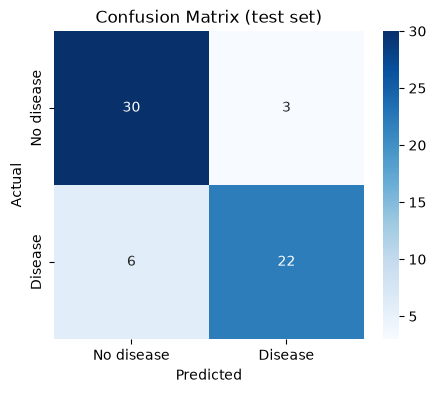

In [12]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Predictions on the 61 unseen test patients
y_pred = pipeline.predict(X_test)

print("=== Test set results ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred):.3f}")

# For comparison: accuracy on the training data
print(f"\nTrain accuracy (for comparison): {accuracy_score(y_train, pipeline.predict(X_train)):.3f}")

# Baseline: always guess the most common class (0 = no disease)
baseline = (y_test == 0).mean()
print(f"Baseline accuracy (always say 'no disease'): {baseline:.3f}")

print("\n=== Confusion matrix (rows = actual, columns = predicted) ===")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\n=== Classification report ===")
print(classification_report(y_test, y_pred, target_names=["No disease (0)", "Disease (1)"]))

# Draw the confusion matrix
plt.close("all")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["No disease", "Disease"],
            yticklabels=["No disease", "Disease"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix (test set)")
plt.show()

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = cross_validate(
    pipeline, X, y, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

print("Accuracy in each of the 5 folds:", results["test_accuracy"].round(3))
for metric in ["accuracy", "precision", "recall", "f1"]:
    scores = results["test_" + metric]
    print(f"{metric:10} mean = {scores.mean():.3f}  (std = {scores.std():.3f})")

Accuracy in each of the 5 folds: [0.754 0.803 0.705 0.783 0.783]
accuracy   mean = 0.766  (std = 0.034)
precision  mean = 0.760  (std = 0.059)
recall     mean = 0.726  (std = 0.037)
f1         mean = 0.741  (std = 0.028)


In [14]:
import joblib
import os
import sklearn

# 1. Save the complete trained pipeline
joblib.dump(pipeline, "heart_disease_model.pkl")
print("Saved to:", os.path.abspath("heart_disease_model.pkl"))
print("File size:", round(os.path.getsize("heart_disease_model.pkl") / 1024, 1), "KB")
print("scikit-learn version used:", sklearn.__version__)

# 2. Load it back as if we were the app
loaded_model = joblib.load("heart_disease_model.pkl")

# 3. The loaded model must give the same answers as the original
same = (loaded_model.predict(X_test) == pipeline.predict(X_test)).all()
print("\nLoaded model gives identical predictions on test set:", same)

# 4. Make a prediction for one new patient (same 4 columns, same order)
new_patient = pd.DataFrame(
    [[1, 4, 120, 1]],          # sex=1 (male), cp=4, thalach=120, exang=1 (yes)
    columns=FEATURES
)
print("\nNew patient:")
display(new_patient)
prediction = loaded_model.predict(new_patient)[0]
probabilities = loaded_model.predict_proba(new_patient)[0]
print("Predicted class:", prediction)
print(f"P(no disease) = {probabilities[0]:.2f}, P(disease) = {probabilities[1]:.2f}")

Saved to: C:\Users\uzair\heart_disease_model.pkl
File size: 3.5 KB
scikit-learn version used: 1.9.1

Loaded model gives identical predictions on test set: True

New patient:


,sex,cp,thalach,exang
0,1,4,120,1


Predicted class: 1
P(no disease) = 0.08, P(disease) = 0.92


In [15]:
import os
import shutil

project = r"C:\HeartDiseaseProject"
os.makedirs(os.path.join(project, "data"), exist_ok=True)

# Copy the trained model into the project folder
shutil.copy("heart_disease_model.pkl", project)

# Copy the dataset files we actually used (and the documentation)
shutil.copy("data/processed.cleveland.data", os.path.join(project, "data"))
shutil.copy("data/heart-disease.names", os.path.join(project, "data"))

print("Project folder:", project)
for root, folders, files in os.walk(project):
    for name in files:
        path = os.path.join(root, name)
        print(" ", os.path.relpath(path, project), f"({os.path.getsize(path)/1024:.1f} KB)")

Project folder: C:\HeartDiseaseProject
  app.py (3.6 KB)
  heart_disease_model.pkl (3.5 KB)
  requirements.txt (0.1 KB)
  data\heart-disease.names (9.8 KB)
  data\processed.cleveland.data (18.0 KB)
  __pycache__\app.cpython-313.pyc (4.9 KB)


In [16]:
%%writefile C:\HeartDiseaseProject\app.py
from pathlib import Path

import joblib
import pandas as pd
import streamlit as st

# The model file sits in the same folder as this app.py
MODEL_PATH = Path(__file__).parent / "heart_disease_model.pkl"

# Same four features, same order as in the notebook
FEATURES = ["sex", "cp", "thalach", "exang"]

# Labels shown to the user -> numbers the model was trained on
SEX_OPTIONS = {"Female": 0, "Male": 1}
CP_OPTIONS = {
    "Typical angina": 1,
    "Atypical angina": 2,
    "Non-anginal pain": 3,
    "Asymptomatic (no chest pain symptoms)": 4,
}
EXANG_OPTIONS = {"No": 0, "Yes": 1}

# The heart-rate range the model saw during training
TRAIN_MIN_HR, TRAIN_MAX_HR = 71, 202

st.set_page_config(page_title="Heart Disease Prediction System", layout="centered")


@st.cache_resource
def load_model(path):
    """Load the saved pipeline once and reuse it."""
    return joblib.load(path)


st.title("Heart Disease Prediction System")
st.write(
    "This app uses a machine learning model trained on the UCI Heart Disease "
    "(Cleveland) dataset. Enter the four details below to get a prediction."
)

st.warning(
    "Educational project only. This is NOT a medical diagnosis tool and is not "
    "a substitute for professional medical advice, diagnosis or treatment. "
    "If you are worried about your health, please see a doctor."
)

# Load the model, and stop politely if something is wrong
try:
    model = load_model(MODEL_PATH)
except FileNotFoundError:
    st.error(
        "Model file 'heart_disease_model.pkl' was not found. Make sure it is in "
        "the same folder as app.py."
    )
    st.stop()
except Exception as error:
    st.error(f"The model could not be loaded: {error}")
    st.stop()

st.subheader("Patient details")

col1, col2 = st.columns(2)
with col1:
    sex_label = st.selectbox("Sex", list(SEX_OPTIONS.keys()))
    thalach = st.number_input(
        "Maximum heart rate achieved (beats per minute)",
        min_value=60, max_value=220, value=150, step=1,
    )
with col2:
    cp_label = st.selectbox("Chest pain type", list(CP_OPTIONS.keys()))
    exang_label = st.selectbox("Exercise-induced angina", list(EXANG_OPTIONS.keys()))

if st.button("Predict"):
    # Build one row with the SAME column names and order used in training
    patient = pd.DataFrame(
        [[
            float(SEX_OPTIONS[sex_label]),
            float(CP_OPTIONS[cp_label]),
            float(thalach),
            float(EXANG_OPTIONS[exang_label]),
        ]],
        columns=FEATURES,
    )

    try:
        prediction = int(model.predict(patient)[0])
        probabilities = model.predict_proba(patient)[0]
    except Exception as error:
        st.error(f"Prediction failed: {error}")
        st.stop()

    st.subheader("Result")

    if prediction == 1:
        st.error("The model predicts: heart disease is LIKELY.")
    else:
        st.success("The model predicts: heart disease is UNLIKELY.")

    left, right = st.columns(2)
    left.metric("Probability of no heart disease", f"{probabilities[0] * 100:.1f}%")
    right.metric("Probability of heart disease", f"{probabilities[1] * 100:.1f}%")
    st.progress(float(probabilities[1]))

    st.caption(
        "The probability is the model's estimate based on only four inputs. "
        "It is not a certainty and can be wrong."
    )

    if thalach < TRAIN_MIN_HR or thalach > TRAIN_MAX_HR:
        st.info(
            f"Note: the model was trained on heart rates between {TRAIN_MIN_HR} and "
            f"{TRAIN_MAX_HR} bpm. Your value is outside that range, so the result "
            "may be less reliable."
        )

Overwriting C:\HeartDiseaseProject\app.py


In [17]:
import py_compile

path = r"C:\HeartDiseaseProject\app.py"
py_compile.compile(path, doraise=True)
print("app.py syntax is OK")

with open(path, encoding="utf-8") as f:
    print("Number of lines:", len(f.readlines()))

app.py syntax is OK
Number of lines: 114


In [18]:
from importlib.metadata import version

packages = ["streamlit", "pandas", "numpy", "scikit-learn", "joblib"]

lines = [f"{name}=={version(name)}" for name in packages]

with open(r"C:\HeartDiseaseProject\requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print("requirements.txt written:\n")
with open(r"C:\HeartDiseaseProject\requirements.txt") as f:
    print(f.read())

requirements.txt written:

streamlit==1.65.0
pandas==3.0.6
numpy==2.5.3
scikit-learn==1.9.1
joblib==1.6.0



In [19]:
import os
import shutil

project = r"C:\HeartDiseaseProject"

# 1. run_app.bat (double-click se app chalane ke liye)
bat_text = r'''@echo off
cd /d "%~dp0"
"C:\Users\uzair\AppData\Local\Programs\Python\Python313\python.exe" -m streamlit run app.py
pause
'''
with open(os.path.join(project, "run_app.bat"), "w") as f:
    f.write(bat_text)

# 2. .gitignore (GitHub ko temporary files ignore karne ke liye)
gitignore_text = """__pycache__/
.ipynb_checkpoints/
*.pyc
.venv/
"""
with open(os.path.join(project, ".gitignore"), "w") as f:
    f.write(gitignore_text)

# 3. Notebook ko project folder mein copy karo
notebooks = [f for f in os.listdir(".") if f.endswith(".ipynb")]
print("Notebooks found in", os.getcwd(), ":", notebooks)
if "Heart_Disease_Prediction.ipynb" in notebooks:
    shutil.copy("Heart_Disease_Prediction.ipynb", project)
    print("Notebook copied.")
else:
    print("Notebook name did not match. Tell me the correct name from the list above.")

print("\nFiles in", project)
for name in sorted(os.listdir(project)):
    print("  ", name)

Notebooks found in C:\Users\uzair : [' Heart_Disease_Prediction.ipynb', 'assign 1.ipynb', 'LAB2.ipynb', 'Untitled.ipynb']
Notebook name did not match. Tell me the correct name from the list above.

Files in C:\HeartDiseaseProject
   .gitignore
   __pycache__
   app.py
   data
   heart_disease_model.pkl
   requirements.txt
   run_app.bat
